# Supplementary Figure S1. Runtime of each annotation tool against RNA size

In [1]:
import json
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import Normalize

def _root() -> Path:
    here = Path.cwd().resolve()
    for base in [here, *here.parents]:
        if (base / "data").is_dir() and (base / "notebooks").is_dir():
            return base
    raise RuntimeError("run this from inside the analysis repo")

ROOT = _root()
data_file = lambda rel: ROOT / "data" / rel
_json = lambda rel: json.loads(data_file(rel).read_text())

def save(fig, rel):
    path = ROOT / rel
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path)
    return path

plt.rcParams.update({
    "figure.dpi": 130, "savefig.dpi": 300, "savefig.bbox": "tight",
    "savefig.pad_inches": 0.08,
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica Neue", "Helvetica", "DejaVu Sans"],
    "font.size": 8.5, "axes.labelsize": 9, "axes.titlesize": 9,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8,
    "axes.linewidth": 0.8, "xtick.major.width": 0.8, "ytick.major.width": 0.8,
    "xtick.direction": "out", "ytick.direction": "out",
    "axes.grid": False, "legend.frameon": False,
    "pdf.fonttype": 42, "ps.fonttype": 42,
})
BLUE, ORANGE, GREEN, RED, GREY = "#4C72B0", "#DD8452", "#55A868", "#C44E52", "0.55"
POINT_FACE, POINT_EDGE, FIT = "#C9C9C9", "0.15", "#111111"

CUT = 80.0

LW = ["cWW", "tWW", "cWH", "tWH", "cWS", "tWS", "cHH", "tHH", "cHS", "tHS", "cSS", "tSS"]
TOOLS = ["parse", "fr3d", "rnaview", "barnaba", "rnapolis", "bpnet"]
TOOL_LABELS = ["FastRNA", "FR3D", "RNAView", "barnaba", "RNApolis", "BPNet"]

def finish(ax):
    for side in ("top", "right", "bottom", "left"):
        ax.spines[side].set_visible(True)
        ax.spines[side].set_linewidth(0.8)
    ax.grid(False)
    ax.tick_params(direction="out", width=0.8, length=3.5)
    return ax

def letter(fig, ax, s, dx=-0.030, dy=0.012):
    box = ax.get_position()
    fig.text(box.x0 + dx, box.y1 + dy, s, fontsize=13, fontweight="bold",
             ha="left", va="bottom")

def pair_scores() -> pd.DataFrame:
    return pd.read_json(data_file("reference/scores/pair_scores_uniques_parse.jsonl"), lines=True)

def scored_pairs(lw_only=True) -> pd.DataFrame:
    df = pair_scores()
    df = df[~df["is_ambiguous"].fillna(False) & df["score"].notna()].copy()
    return df[df["lw_class"].isin(LW)].copy() if lw_only else df

def _resolution(m):
    if not isinstance(m, dict):
        return None
    return (m.get("EM Diffraction Resolution (Å)") or m.get("Refinement_resolution")
            or m.get("EM Resolution (Å)"))

def structure_scores() -> pd.DataFrame:
    sc = _json("reference/scores/scores_all_uniques.json")["scores"]
    md = _json("reference/metadata/metadata_cache.json")
    vm, nt = md["validation_metrics"], md["nucleotide_counts"]
    rows = []
    for pdb, info in sc.items():
        m = vm.get(pdb) if isinstance(vm.get(pdb), dict) else {}
        rows.append({"pdb": pdb, "pairs_score": info.get("pairs_score"),
                     "backbone_suiteness": info.get("backbone_suiteness"),
                     "n_pairs": info.get("n_pairs", 0),
                     "n_residues_scored": info.get("n_residues_scored", 0),
                     "method": m.get("Experimental_method"),
                     "resolution": _resolution(m), "clashscore": m.get("clashscore"),
                     "rnasuiteness": m.get("rnasuiteness"),
                     "n_nucleotides": nt.get(pdb),
                     "deposited": m.get("Deposition_Date")})
    return pd.DataFrame(rows)

def runtime() -> pd.DataFrame:
    df = pd.read_csv(data_file("benchmark/dssr_PARSE_time_benchmark.csv"))
    df = df[(df["Nucleotides"] > 0) & (df["dssr_avg"] > 0) & (df["parse_avg"] > 0)].copy()
    df["ratio"] = df["dssr_avg"] / df["parse_avg"]
    return df

WEIGHTS = _json("reference/scoring_tables/penalty_weights.json")["penalty_weights"]
ISSUES = list(WEIGHTS)
ISSUE_LABELS = {"distance": "H-bond distance", "hbond_angles": "H-bond angles",
                "incorrect_hbond_count": "H-bond count", "stretch": "Stretch",
                "opening": "Opening", "stagger": "Stagger", "propeller": "Propeller",
                "shear": "Shear", "buckle": "Buckle", "clash": "Clash"}

def hist_grid(fig, spec, df, params, xlabel, cols=3):
    rows = int(np.ceil(len(params) / cols))
    sub = spec.subgridspec(rows, cols, wspace=0.42, hspace=0.62)
    axes = []
    for i, p in enumerate(params):
        ax = fig.add_subplot(sub[i // cols, i % cols])
        vals = pd.to_numeric(df[p], errors="coerce").dropna()
        if len(vals) > 20000:
            vals = vals.sample(20000, random_state=1)
        ax.hist(vals, bins=40, color=BLUE, alpha=0.8)
        ax.set_xlabel(p.replace("_", " "), fontsize=7.5)
        ax.tick_params(labelsize=6.5)
        if i % cols == 0:
            ax.set_ylabel("Count", fontsize=7.5)
        finish(ax)
        axes.append(ax)
    return axes

AXIS_LABEL_PT = 8.5


def enlarge_axis_labels(fig, text_pt=7.0, axis_pt=AXIS_LABEL_PT):
    for ax in fig.axes:
        for lab in (ax.xaxis.label, ax.yaxis.label):
            if lab.get_text().strip():
                lab.set_fontsize(lab.get_fontsize() * axis_pt / text_pt)


## Panels A-F
Runtime of each annotation tool and of FastRNA as a function of RNA size, one panel per tool

DSSR: 2,096 structures


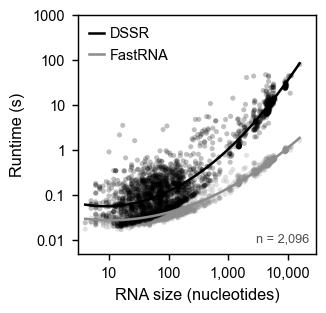

BPNet: 2,065 structures


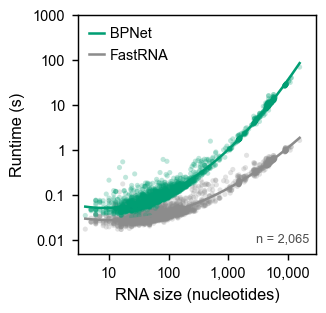

RNAView: 2,045 structures


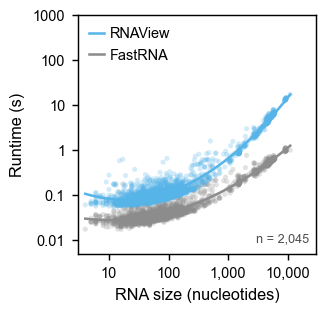

FR3D: 2,096 structures


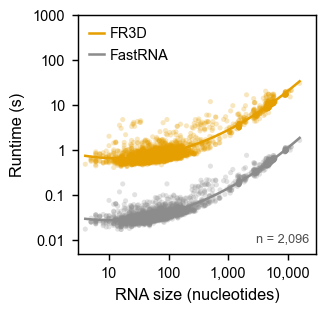

barnaba: 2,090 structures


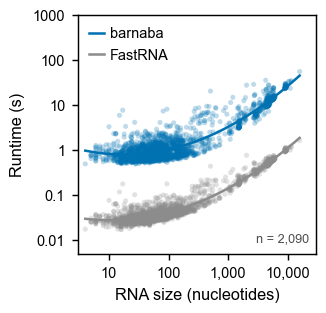

RNApolis: 2,095 structures


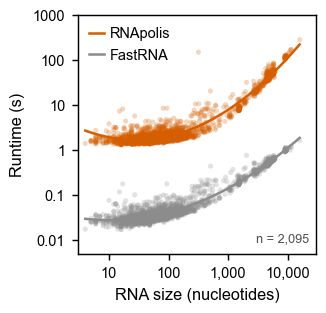

In [2]:
from matplotlib.ticker import FixedLocator, FuncFormatter

RUNTIME_TOOLS = [
    ("dssr", "DSSR", "#000000"), ("bpnet", "BPNet", "#009E73"),
    ("rnaview", "RNAView", "#56B4E9"), ("fr3d", "FR3D", "#E69F00"),
    ("barnaba", "barnaba", "#0072B2"), ("rnapolis", "RNApolis", "#D55E00")]
FASTRNA_GREY = "0.55"


def runtimes():
    ps = pd.read_csv(data_file("benchmark/runtime_direct_all/per_structure.csv"))
    return ps.pivot(index=["pdb", "nucleotides"], columns="tool",
                    values="median_seconds").reset_index()


RT = runtimes()


def draw_runtime(ax, tool, label, colour, show_ylabel=True, compact=False):
    d = RT.dropna(subset=[tool, "parse"])
    n = d["nucleotides"].to_numpy()
    fit = lambda t: np.polyfit(np.log10(n), np.log10(t), 2)
    xs = np.logspace(np.log10(n.min()), np.log10(n.max()), 200)
    s = 3 if compact else 8
    for col, c, name in (("parse", FASTRNA_GREY, "FastRNA"), (tool, colour, label)):
        t = d[col].to_numpy()
        ax.scatter(n, t, s=s, alpha=0.25, color=c, edgecolors="none", rasterized=True)
        ax.plot(xs, 10 ** np.polyval(fit(t), np.log10(xs)), color=c, lw=1.4, label=name)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlim(3, 3e4); ax.set_ylim(0.005, 1000)
    ax.xaxis.set_major_locator(FixedLocator([10, 100, 1000, 10000]))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.yaxis.set_major_locator(FixedLocator([0.01, 0.1, 1, 10, 100, 1000]))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
    ax.xaxis.set_minor_locator(plt.NullLocator())
    ax.yaxis.set_minor_locator(plt.NullLocator())
    ax.set_xlabel("RNA size (nucleotides)")
    ax.set_ylabel("Runtime (s)" if show_ylabel else "")
    handles, names = ax.get_legend_handles_labels()
    ax.legend(handles[::-1], names[::-1], loc="upper left", handlelength=1.0,
              handletextpad=0.4, borderaxespad=0.4)
    ax.text(0.97, 0.04, f"n = {len(d):,}", transform=ax.transAxes, ha="right", va="bottom",
            fontsize=7, color="0.3")
    finish(ax)
    ax.set_box_aspect(1)
    return len(d)


for letter_, (tool, label, colour) in zip("ABCDEF", RUNTIME_TOOLS):
    fig, ax = plt.subplots(figsize=(2.6, 2.6))
    print(f"{label}: {draw_runtime(ax, tool, label, colour):,} structures")
    fig.tight_layout()
    save(fig, f"figures/supplemental/figS1_{letter_}_runtime_{tool}.png")
    plt.show()

## Panel G
FastRNA speed-up over each annotation tool as a function of RNA size

2,096 structures


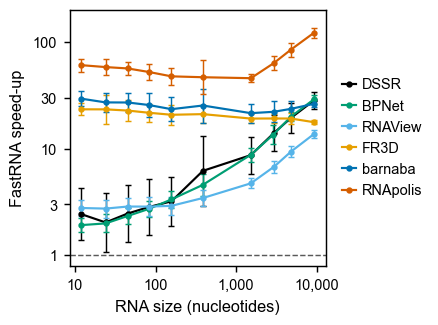

In [3]:
N_BINS, MIN_PER_BIN = 12, 30


def speedups():
    s = pd.read_csv(data_file("benchmark/runtime_direct_all/speedups.csv"))
    return s[s["baseline"] == "parse"]


def size_groups(sp, n_bins=N_BINS, min_per_bin=MIN_PER_BIN):
    structs = sp[["pdb", "nucleotides"]].drop_duplicates()
    log_n = np.log10(structs["nucleotides"].to_numpy())
    edges = np.linspace(log_n.min(), log_n.max(), n_bins + 1)
    idx = np.clip(np.digitize(log_n, edges) - 1, 0, n_bins - 1)
    bins = [[k] for k in range(n_bins) if (idx == k).any()]
    count = lambda b: sum((idx == k).sum() for k in b)
    while len(bins) > 1 and min(count(b) for b in bins) < min_per_bin:
        i = min(range(len(bins)), key=lambda j: count(bins[j]))
        nbrs = [j for j in (i - 1, i + 1) if 0 <= j < len(bins)]
        j = min(nbrs, key=lambda j: count(bins[j]))
        lo, hi = sorted((i, j))
        bins[lo:hi + 1] = [bins[lo] + bins[hi]]
    to_bin = {k: g for g, b in enumerate(bins) for k in b}
    return dict(zip(structs["pdb"], (to_bin[k] for k in idx)))


def draw_speedup(ax):
    sp = speedups()
    sp = sp.assign(group=sp["pdb"].map(size_groups(sp)), log_speedup=np.log(sp["speedup"]))
    for tool, name, colour in RUNTIME_TOOLS:
        g = sp[sp["tool"] == tool].groupby("group")
        xs = (10 ** g["nucleotides"].apply(lambda n: np.median(np.log10(n)))).to_numpy()
        gmean = np.exp(g["log_speedup"].mean().to_numpy())
        gsd = np.exp(g["log_speedup"].std().to_numpy())
        ax.errorbar(xs, gmean, yerr=[gmean - gmean / gsd, gmean * gsd - gmean], color=colour,
                    lw=1.2, marker="o", ms=2.5, elinewidth=0.8, capsize=1.5, capthick=0.8)
    ax.axhline(1, color="0.35", ls="--", lw=0.8)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_ylim(0.8, 200)
    handles = [plt.Line2D([], [], color=colour, lw=1.2, marker="o", ms=2.5, label=name)
               for _, name, colour in RUNTIME_TOOLS]
    ax.legend(handles=handles, loc="center left", bbox_to_anchor=(1.04, 0.5),
              handlelength=1.0, handletextpad=0.4, borderaxespad=0.0)
    ax.xaxis.set_major_locator(FixedLocator([10, 100, 1000, 10000]))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.yaxis.set_major_locator(FixedLocator([1, 3, 10, 30, 100]))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
    ax.xaxis.set_minor_locator(plt.NullLocator())
    ax.yaxis.set_minor_locator(plt.NullLocator())
    ax.set_xlabel("RNA size (nucleotides)")
    ax.set_ylabel("FastRNA speed-up")
    finish(ax)
    ax.set_box_aspect(1)
    return sp["pdb"].nunique()


fig, ax = plt.subplots(figsize=(3.6, 2.6))
print(f"{draw_speedup(ax):,} structures")
fig.tight_layout()
save(fig, "figures/supplemental/figS1_G_speedup.png")
plt.show()


## Combined figure


text scaled x1.00: 7 pt prints at 7.0 pt at page width


axis titles print at 8.5 pt and panel letters at 12.0 pt (6.69 in saved, shown at 6.69 in)


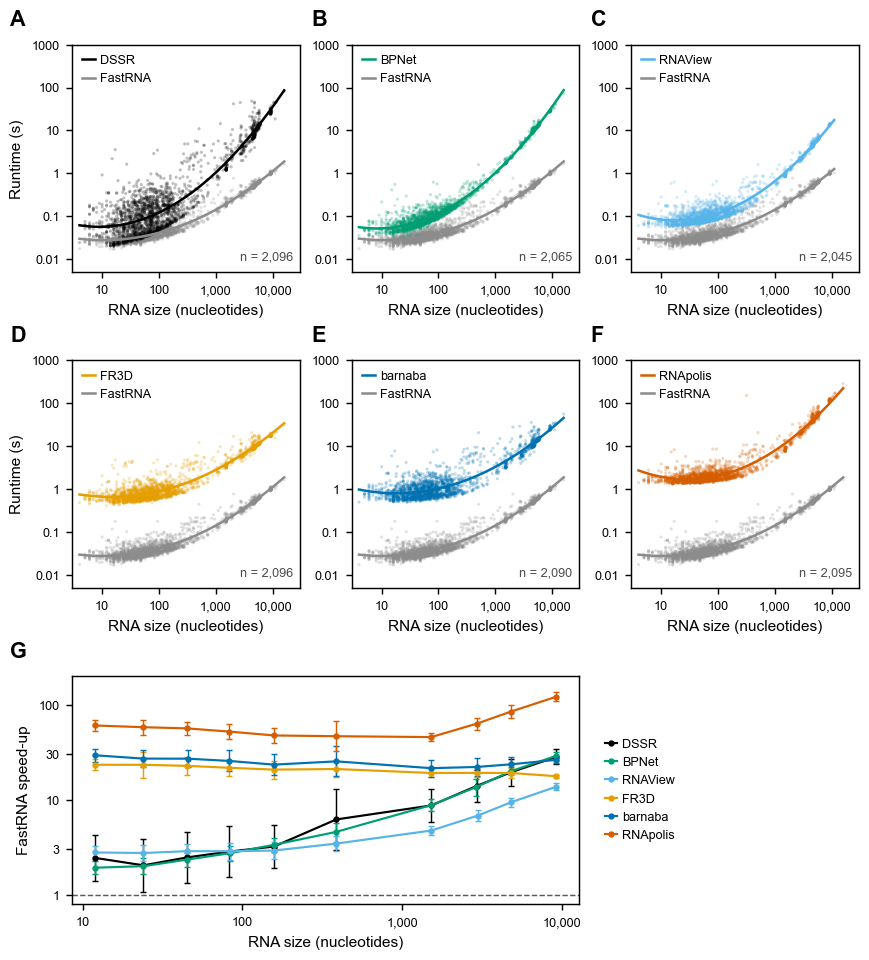

In [4]:
plt.rcParams.update({"xtick.labelsize": 7, "ytick.labelsize": 7, "axes.labelsize": 8,
                     "legend.fontsize": 7})
LABEL_IN, PANEL_IN, COL_GAP = 0.55, 1.75, 0.40
COL_X = [LABEL_IN + k * (PANEL_IN + COL_GAP) for k in range(3)]
RIGHT = COL_X[-1] + PANEL_IN
G_H = PANEL_IN
FIG_W, FIG_H = RIGHT + 0.08, 3 * (PANEL_IN + 0.8) + G_H
fig = plt.figure(figsize=(FIG_W, FIG_H))
inch = lambda x, y, w, h: [x / FIG_W, 1 - (y + h) / FIG_H, w / FIG_W, h / FIG_H]
ax_rt = [fig.add_axes(inch(COL_X[k % 3], 0.3 + (k // 3) * (PANEL_IN + 0.8), PANEL_IN, PANEL_IN))
         for k in range(6)]
for k, (ax, (tool, label, colour)) in enumerate(zip(ax_rt, RUNTIME_TOOLS)):
    draw_runtime(ax, tool, label, colour, show_ylabel=(k % 3 == 0), compact=True)
    ax.set_box_aspect(None)
ax_g = fig.add_axes(inch(LABEL_IN, 0.3 + 2 * (PANEL_IN + 0.8), COL_X[1] + PANEL_IN - LABEL_IN, G_H))
draw_speedup(ax_g)
ax_g.set_box_aspect(None)
inv = fig.transFigure.inverted()

fig.canvas.draw()
renderer = fig.canvas.get_renderer()
x_left = ax_rt[0].get_tightbbox(renderer).transformed(inv).x0
for ax, s in zip([*ax_rt, ax_g], "ABCDEFG"):
    x = x_left if s == "G" else ax.get_tightbbox(renderer).transformed(inv).x0
    fig.text(x, ax.get_position().y1 + 0.012, s, fontsize=12, fontweight="bold",
             ha="left", va="bottom")
TEXT_PT, LETTER_PT = 7, 12


def set_uniform_text(fig, size=TEXT_PT):
    import matplotlib.text as mtext
    for t in fig.findobj(mtext.Text):
        if t.get_fontsize() >= LETTER_PT and t.get_fontweight() in ("bold", 700):
            continue
        t.set_fontsize(size)


set_uniform_text(fig)
enlarge_axis_labels(fig)

ROW_GAP_IN = 0.06


def restack_rows(fig, rows, gap_in=ROW_GAP_IN, margin_in=0.05, extras=()):
    fig.canvas.draw()
    r = fig.canvas.get_renderer()
    W, H = fig.get_size_inches()
    ft = lambda y_px: H - y_px / fig.dpi
    tops = [min(ft(a.get_tightbbox(r).y1) for a in row) for row in rows]
    bots = [max(ft(a.get_tightbbox(r).y0) for a in row) for row in rows]

    def row_of(y_ft):
        below = [i for i in range(len(rows)) if y_ft <= bots[i]]
        return min(below, key=lambda i: abs(tops[i] - y_ft)) if below else len(rows) - 1

    texts = [(t, row_of(ft(t.get_window_extent(r).y0))) for t in fig.texts]
    for t, i in texts:
        e = t.get_window_extent(r)
        tops[i], bots[i] = min(tops[i], ft(e.y1)), max(bots[i], ft(e.y0))
    deltas, cursor = [], margin_in
    for top, bot in zip(tops, bots):
        deltas.append(cursor - top)
        cursor += bot - top + gap_in
    H2 = cursor - gap_in + margin_in
    for a, i in extras:
        H2 = max(H2, H - a.get_position(original=True).y0 * H + deltas[i] + margin_in)
    fig.set_size_inches(W, H2)
    conv = lambda y_frac, d: (H2 - (H - y_frac * H + d)) / H2

    def move(a, d):
        p = a.get_position(original=True)
        a.set_position([p.x0, conv(p.y0, d), p.width, p.height * H / H2], which="both")

    for i, row in enumerate(rows):
        for a in row:
            move(a, deltas[i])
    for a, i in extras:
        move(a, deltas[i])
    for t, i in texts:
        x, y = t.get_position()
        t.set_position((x, conv(y, deltas[i])))
    for art in fig.artists:
        if hasattr(art, "_posA_posB") and art._posA_posB:
            (xa, ya), (xb, yb) = art._posA_posB
            d = deltas[row_of(H - ya * H)]
            art.set_positions((xa, conv(ya, d)), (xb, conv(yb, d)))

restack_rows(fig, [ax_rt[:3], ax_rt[3:], [ax_g]])
import matplotlib.text as _mtext
def _print_scale(fig, page_in=6.73, pad=0.08):
    fig.canvas.draw()
    bb = fig.get_tightbbox(fig.canvas.get_renderer())
    return max(1.0, (bb.width + 2 * pad) / page_in)
fig.canvas.draw()
_texts = [t for t in fig.findobj(_mtext.Text) if t.get_text().strip()]
_base = {t: t.get_fontsize() for t in _texts}
_s = 1.0
for _ in range(6):
    _need = _print_scale(fig)
    if _s >= _need - 1e-3:
        break
    _s = _need * 1.01
    for _t in _texts:
        _t.set_fontsize(_base[_t] * _s)
print(f"text scaled x{_s:.2f}: 7 pt prints at {7 * _s / _print_scale(fig):.1f} pt "
      f"at page width")
def _set_print_sizes(fig, axis_pt=8.5, letter_pt=12.0, page_in=6.73, pad=0.08):
    letters = [t for t in fig.texts if t.get_text().strip().isalpha()
               and t.get_text().strip().isupper() and len(t.get_text().strip()) <= 2
               and t.get_fontweight() in ("bold", 700)]
    for _ in range(8):
        fig.canvas.draw()
        bb = fig.get_tightbbox(fig.canvas.get_renderer())
        shrink = max(1.0, (bb.width + 2 * pad) / page_in)
        for ax in fig.axes:
            for lab in (ax.xaxis.label, ax.yaxis.label):
                if lab.get_text().strip():
                    lab.set_fontsize(axis_pt * shrink)
        for t in letters:
            t.set_fontsize(letter_pt * shrink)
    print(f"axis titles print at {axis_pt} pt and panel letters at {letter_pt} pt "
          f"({bb.width + 2 * pad:.2f} in saved, shown at {min(page_in, bb.width + 2 * pad):.2f} in)")


_set_print_sizes(fig)

save(fig, "figures/supplemental/figS1.png")
plt.show()
